# 05 · Model performance across subgroups

Produces **Supplementary Table 6** and **Supplementary Figure 5**: held-out test-set RMSE (fractional
iron absorption, %) with bootstrap 95% CIs (2000 resamples), overall and by administration route, study
site, iron status and iron compound. Subgroups with fewer than 10 test measurements are not estimated.

In [1]:
import os, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error

pd.set_option("display.width", 120)
RANDOM_STATE = 42
FINAL_PARAMS = {"colsample_bytree": 0.7, "learning_rate": 0.05, "max_depth": 8, "n_estimators": 400, "subsample": 0.8}
FEATURES = ["Age (y)", "Isotope", "Meal type", "Fe compound", "Fe dose", "Vitamin C dose",
                "Calcium dose", "Zinc dose ", "Polyphenol dose", "Phytic acid dose",
                "C-reactive protein", "Hep", "Ferritin", "Hb", "BMI", "BV", "Fe.circ"]
os.makedirs("../results", exist_ok=True)
os.makedirs("../figures/panels", exist_ok=True)

## 1. Final model and held-out test set

In [2]:
raw = pd.read_excel("../data/pooled_dataset.xls")
d = raw.copy()
d["Meal type"] = d["Meal type"].fillna("Supplement")
d["Isotope"] = d["Isotope"].fillna("Unknown")
for col in FEATURES:
    if d[col].dtype == object:
        d[col] = d[col].astype("category").cat.codes
d = d[d[FEATURES + ["Fe absorption (%)"]].isnull().sum(axis=1) < 14]

y = np.log10(d["Fe absorption (%)"] + 1)
X = d[FEATURES]
X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
    X, y, d.index, test_size=0.20, random_state=RANDOM_STATE)

model = xgb.XGBRegressor(objective="reg:squarederror", random_state=RANDOM_STATE, n_jobs=-1, **FINAL_PARAMS)
model.fit(X_train, y_train)
obs_pct = 10 ** y_test.values - 1
pred_pct = 10 ** model.predict(X_test) - 1
print("Held-out test set:", len(idx_test))

Held-out test set: 1012


## 2. Subgroups

In [3]:
def consolidate_compound(x):
    x = str(x).strip()
    if x == "Fe sulfate":
        return "Ferrous sulfate"
    if x in ("Fe fumarate", "Fe Fumarate"):
        return "Ferrous fumarate"
    if x in ("Fe pyrophosphate", "FePP"):
        return "Ferric pyrophosphate"
    if x == "NaFeEDTA":
        return "Sodium iron EDTA"
    return "Other/combination"

labels = raw.loc[idx_test].copy()
labels["Route"] = labels["Meal or Supplement"]
labels["Study site"] = labels["Site"]
labels["Iron compound"] = labels["Fe compound"].apply(consolidate_compound)
# Iron deficiency: serum ferritin < 15 ug/L and/or sTfR > 8.3 mg/L (Methods)
deficient = (labels["Ferritin"] < 15).fillna(False) | (labels["sTfR"] > 8.3).fillna(False)
unknown = labels["Ferritin"].isna() & labels["sTfR"].isna()
labels["Iron status"] = np.where(unknown, "Unknown", np.where(deficient, "Iron deficient", "Not iron deficient"))

## 3. Supplementary Table 6

In [4]:
def bootstrap_rmse_ci(obs, pred, B=2000, random_state=RANDOM_STATE, min_n=10):
    n = len(obs)
    if n < min_n:
        return np.nan, np.nan, np.nan, n
    rng = np.random.default_rng(random_state)
    idx = np.arange(n); stats = np.empty(B)
    for b in range(B):
        bs = rng.choice(idx, size=n, replace=True)
        stats[b] = root_mean_squared_error(obs[bs], pred[bs])
    lo, hi = np.percentile(stats, [2.5, 97.5])
    return root_mean_squared_error(obs, pred), lo, hi, n

cols = ["RMSE", "CI lower", "CI upper", "n"]
rows = [{"Group": "Overall", "Subgroup": "Overall", **dict(zip(cols, bootstrap_rmse_ci(obs_pct, pred_pct)))}]
for group in ["Route", "Study site", "Iron status", "Iron compound"]:
    for level in labels[group].dropna().unique():
        if level == "Unknown":
            continue
        mask = (labels[group] == level).values
        rows.append({"Group": group, "Subgroup": level,
                     **dict(zip(cols, bootstrap_rmse_ci(obs_pct[mask], pred_pct[mask])))})
supp_table6 = pd.DataFrame(rows).round(2)
print(supp_table6.to_string(index=False))
supp_table6.to_csv("../results/supp_table6_subgroups.csv", index=False)

        Group             Subgroup  RMSE  CI lower  CI upper    n
      Overall              Overall  8.01      7.16      8.88 1012
        Route                 Meal  6.85      6.13      7.55  743
        Route           Supplement 10.57      8.51     12.64  269
   Study site          Switzerland  8.08      7.10      9.17  827
   Study site               Mexico  7.67      5.00     10.26   43
   Study site             Thailand  8.50      4.16     12.48   37
   Study site              Lebanon  5.57      3.04      7.96   20
   Study site                Haiti  9.15      3.56     13.62   18
   Study site              Morocco  6.88      4.46      8.74   13
   Study site                Benin 13.96      9.47     17.48   11
   Study site                India  5.12      3.37      6.73   28
   Study site               Taiwan  2.66      1.78      3.40   15
  Iron status   Not iron deficient  7.46      6.62      8.22  547
  Iron status       Iron deficient  9.53      7.60     11.66  307
Iron compo

## 4. Supplementary Figure 5: forest plot

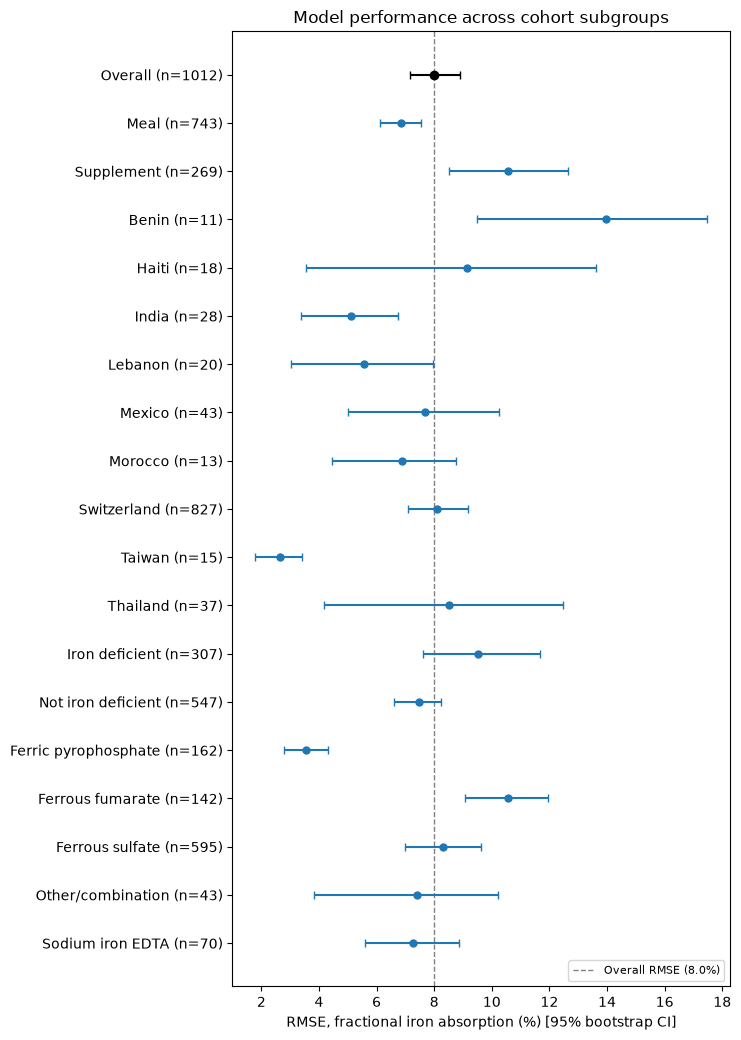

In [5]:
order = ["Overall", "Route", "Study site", "Iron status", "Iron compound"]
plot_df = pd.concat([supp_table6[supp_table6["Group"] == g] if g == "Overall"
                     else supp_table6[supp_table6["Group"] == g].sort_values("Subgroup") for g in order])
plot_df = plot_df.iloc[::-1].reset_index(drop=True)

fig, ax = plt.subplots(figsize=(7.5, max(3, 0.5 * len(plot_df) + 1)))
overall = supp_table6.loc[supp_table6["Group"] == "Overall", "RMSE"].iloc[0]
ax.axvline(overall, color="grey", linestyle="--", linewidth=1, zorder=0, label=f"Overall RMSE ({overall:.1f}%)")
for i, r in plot_df.iterrows():
    is_overall = r["Group"] == "Overall"
    if pd.isna(r["RMSE"]):
        ax.text(overall, i, f"  n={int(r['n'])} (too small to estimate)", va="center", fontsize=8, color="grey")
        continue
    ax.errorbar(r["RMSE"], i, xerr=[[r["RMSE"] - r["CI lower"]], [r["CI upper"] - r["RMSE"]]], fmt="o",
                color="black" if is_overall else "tab:blue", capsize=3, markersize=6 if is_overall else 5)
ax.set_yticks(np.arange(len(plot_df)))
ax.set_yticklabels([f"{r['Subgroup']} (n={int(r['n'])})" for _, r in plot_df.iterrows()])
ax.set_xlabel("RMSE, fractional iron absorption (%) [95% bootstrap CI]")
ax.set_title("Model performance across cohort subgroups")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig("../figures/panels/SuppFig5.png", dpi=150, bbox_inches="tight")
plt.show()